# Customer Churn & Retention Analytics
### Business Management × Data Science

The IBM Telco sample represents a **fictional company**. All rand figures in the scenario are separately assumed; they are **not converted dataset charges**.

In [1]:
from pathlib import Path
import pandas as pd
import json
ROOT=Path.cwd()
if not (ROOT/'reports/model_summary.json').exists(): ROOT=ROOT.parent
summary=json.loads((ROOT/'reports/model_summary.json').read_text())
summary

{'selected_model': 'Random Forest',
 'test_rows': 1409,
 'test_churn_count': 374,
 'holdout_roc_auc': 0.8412746389728487,
 'holdout_average_precision': 0.6434165728719777,
 'baseline_churn_prevalence': 0.2654364797728886,
 'holdout_brier_score': 0.13749945968427393,
 'threshold': 0.5,
 'precision': 0.6460481099656358,
 'recall': 0.5026737967914439,
 'f1': 0.5654135338345865,
 'true_negative': 932,
 'false_positive': 103,
 'false_negative': 186,
 'true_positive': 188,
 'top_20pct_holdout_churn_capture': 0.4946524064171123,
 'top_20pct_holdout_churn_rate': 0.6560283687943262}

## 1. Business question
Which customers should be contacted, and does retention outreach justify its cost? Historical churn probability is **not** treatment responsiveness.

In [2]:
df=pd.read_csv(ROOT/'data/processed/telco_customer_churn_clean.csv')
print('Records:',len(df),'Churn rate:',round(df.ChurnFlag.mean(),3))
df.groupby('Contract').ChurnFlag.agg(['mean','size'])

Records: 7043 Churn rate: 0.265


,mean,size
Contract,,
Month-to-month,0.427097,3875
One year,0.112695,1473
Two year,0.028319,1695


## 2. Model selection using development data only
All imputation and encoding happen within training folds. The hold-out does not select the model.

In [3]:
pd.read_csv(ROOT/'reports/cross_validation.csv')

,model,cv_roc_auc_mean,cv_roc_auc_std,cv_average_precision_mean
0,Random Forest,0.845890,0.008038,0.657750
1,Logistic Regression,0.844911,0.012161,0.659657
2,Decision Tree,0.830265,0.009664,0.618627


## 3. Independent test performance
A confusion matrix measures threshold behaviour; Brier score and calibration diagnose probability quality.

In [4]:
pd.read_csv(ROOT/'reports/model_metrics.csv').T

,0
selected_model,Random Forest
test_rows,1409
test_churn_count,374
holdout_roc_auc,0.841275
holdout_average_precision,0.643417
baseline_churn_prevalence,0.265436
holdout_brier_score,0.137499
threshold,0.5
precision,0.646048
recall,0.502674


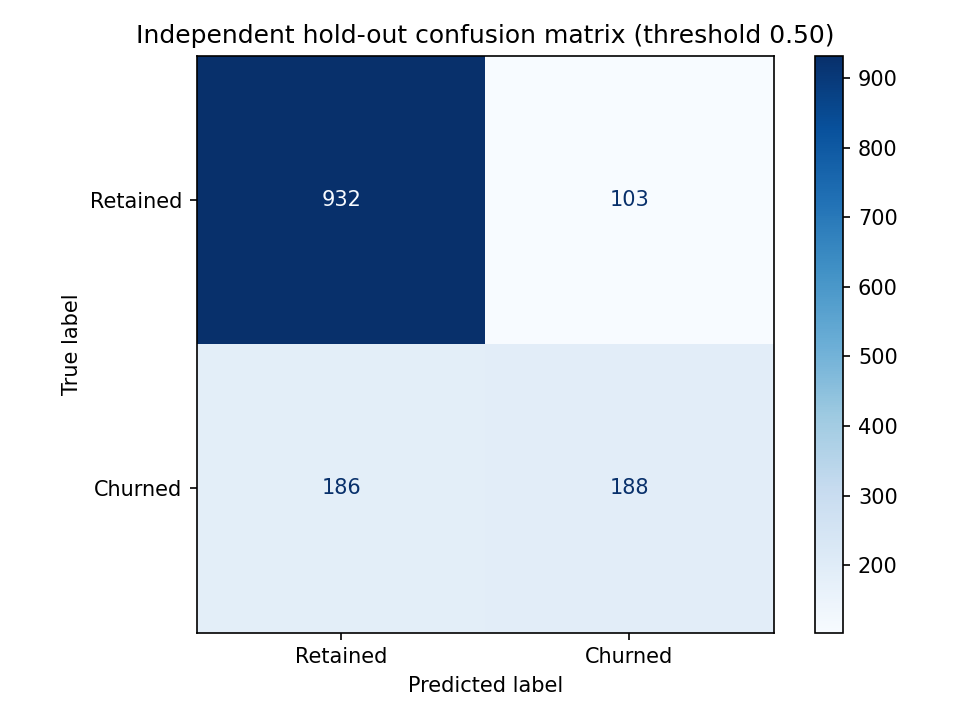

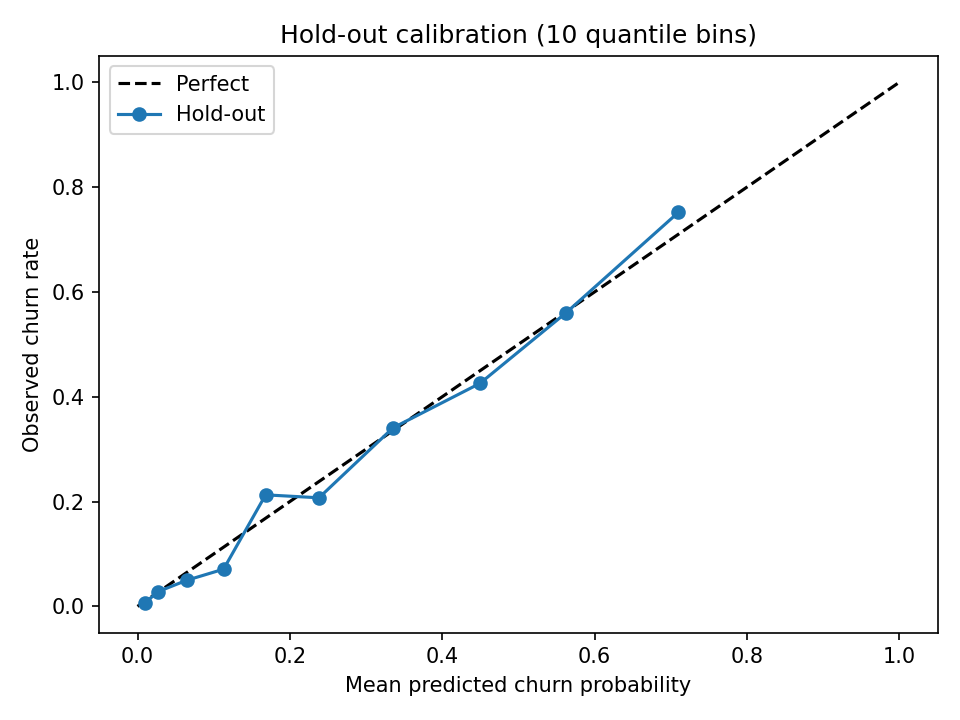

In [5]:
from IPython.display import display,Image
display(Image(filename=str(ROOT/'visualisations/holdout_confusion_matrix.png')))
display(Image(filename=str(ROOT/'visualisations/holdout_calibration.png')))

## 4. Correlated-feature caveat
`TotalCharges` is a cumulative billing measure strongly related to `tenure` and `MonthlyCharges`. It is excluded from the primary model. Neither this nor other associations establish causality.

In [6]:
pd.read_csv(ROOT/'reports/correlated_feature_sensitivity.csv')

,primary_excludes_TotalCharges,selected_model_holdout_auc,logistic_with_TotalCharges_holdout_auc,note
0,True,0.841275,0.841861,Sensitivity only; correlated variables are not...


## 5. Segment opportunities and the business case
Segment patterns suggest **where to investigate**, not which interventions will work. The rand-value case assumes R1,000 monthly revenue, 30% margin, six months, R150 per contact and 10% incremental retention uplift. No causal uplift is estimated from this dataset.

In [7]:
pd.read_csv(ROOT/'reports/holdout_segment_opportunities.csv').sort_values('observed_churn_rate',ascending=False).head(8)

,Contract,InternetService,customers,observed_churn_rate,average_monthly_charges_dataset_units,average_model_probability
1,Month-to-month,Fiber optic,421,0.527316,86.185867,0.542986
0,Month-to-month,DSL,250,0.340000,50.711800,0.317139
4,One year,Fiber optic,103,0.223301,97.601456,0.202036
2,Month-to-month,No,102,0.215686,20.266667,0.179363
3,One year,DSL,118,0.084746,61.962288,0.102228
7,Two year,Fiber optic,89,0.078652,104.897191,0.106823
5,One year,No,79,0.037975,20.550000,0.032771
6,Two year,DSL,116,0.017241,69.871983,0.037957


In [8]:
pd.read_csv(ROOT/'reports/retention_scenario_sensitivity.csv')

,contact_cost_R,assumed_incremental_retention_uplift,customers_contacted,hypothetical_incremental_contribution_R,hypothetical_contact_cost_R,hypothetical_net_value_R
0,50,0.05,282,16148.481106,14100,2048.481106
1,50,0.10,282,32296.962213,14100,18196.962213
2,50,0.20,282,64593.924425,14100,50493.924425
3,100,0.05,282,16148.481106,28200,-12051.518894
4,100,0.10,282,32296.962213,28200,4096.962213
5,100,0.20,282,64593.924425,28200,36393.924425
6,150,0.05,282,16148.481106,42300,-26151.518894
7,150,0.10,282,32296.962213,42300,-10003.037787
8,150,0.20,282,64593.924425,42300,22293.924425
9,250,0.05,282,16148.481106,70500,-54351.518894


## 6. Management recommendation
Do not launch an expensive retention campaign based solely on churn scores. Validate on later cohorts, A/B test offers to measure **incremental** retention, verify customer lifetime value and outreach costs, and monitor fairness, privacy and customer experience.